# ARTI 502 – Assignment 2

## Task 1 – Getting the CIFAR Dataset

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

path = "./data"
change = transforms.ToTensor()

train_data = torchvision.datasets.CIFAR10(
    root=path,
    train=True,
    download=True,
    transform=change
)

test_data = torchvision.datasets.CIFAR10(
    root=path,
    train=False,
    download=True,
    transform=change
)

print("Train:", len(train_data))
print("Test:", len(test_data))

100%|██████████| 170M/170M [21:56<00:00, 130kB/s]


Train: 50000
Test: 10000


## Task 2 – Defining the Network

In [3]:
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Train batches: 782
Test batches: 157


In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [5]:
model = CNN().to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [6]:
def test(model, loader, loss_fn):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            output = model(images)
            loss = loss_fn(output, labels)

            total_loss += loss.item() * images.size(0)
            correct += (output.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total

In [7]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        n += x.size(0)
    return total_loss / n


In [8]:
images, labels = next(iter(train_loader))

output = model(images.to(device))

print("Input:", images.shape)
print("Output:", output.shape)

Input: torch.Size([64, 3, 32, 32])
Output: torch.Size([64, 10])


## Task 3 – Loading Data

In [9]:

# Task 3: Inspecting image tensor dimensions

images, labels = next(iter(train_loader))

print("Images tensor shape:", images.shape)
print("Labels tensor shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel value range:", images.min().item(), "to", images.max().item())
print("Number of images in batch:", images.size(0))
print("Number of channels:", images.size(1))
print("Image height:", images.size(2))
print("Image width:", images.size(3))


Images tensor shape: torch.Size([64, 3, 32, 32])
Labels tensor shape: torch.Size([64])
Image data type: torch.float32
Pixel value range: 0.0 to 1.0
Number of images in batch: 64
Number of channels: 3
Image height: 32
Image width: 32


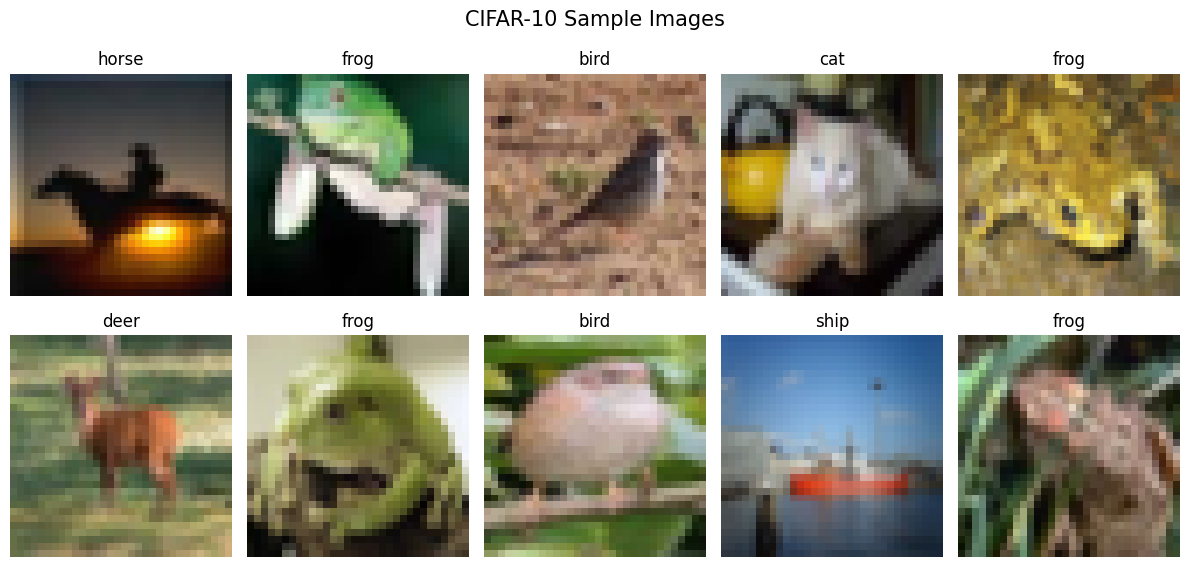

In [10]:

# Task 3: Visualizing CIFAR-10 images

import matplotlib.pyplot as plt
import numpy as np

class_names = train_data.classes

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Images", fontsize=15)
plt.tight_layout()
plt.show()


## Task 4 – Dataset Augmentation

In [11]:

# Task 4: Individual augmentation techniques

import torchvision.transforms as transforms
from PIL import Image

# Load an original image without any transformations
original_image, original_label = train_data.data[0], train_data.targets[0]
original_image = Image.fromarray(original_image)

augmentation_methods = {
    "Original": transforms.Compose([
        transforms.ToTensor()
    ]),

    "ToPILImage": transforms.Compose([
        transforms.ToTensor(),
        transforms.ToPILImage(),   # tensor -> PIL image
        transforms.ToTensor()      # PIL image -> tensor again
    ]),

    "Horizontal Flip": transforms.Compose([
        transforms.RandomHorizontalFlip(p=1.0),
        transforms.ToTensor()
    ]),

    "Random Crop": transforms.Compose([
        transforms.RandomResizedCrop(
            size=32,
            scale=(0.7, 0.9)
        ),
        transforms.ToTensor()
    ]),

    "Rotation": transforms.Compose([
        transforms.RandomRotation(degrees=(25, 25)),
        transforms.ToTensor()
    ]),

    "Color Jitter": transforms.Compose([
        transforms.ColorJitter(
            brightness=0.5,
            contrast=0.5,
            saturation=0.5,
            hue=0.1
        ),
        transforms.ToTensor()
    ]),

    "Gaussian Noise": transforms.Compose([
        transforms.ToTensor(),
        transforms.Lambda(
            lambda x: torch.clamp(
                x + torch.randn_like(x) * 0.08,
                0, 1
            )
        )
    ])
}

print("Number of augmentation methods:", len(augmentation_methods))


Number of augmentation methods: 7


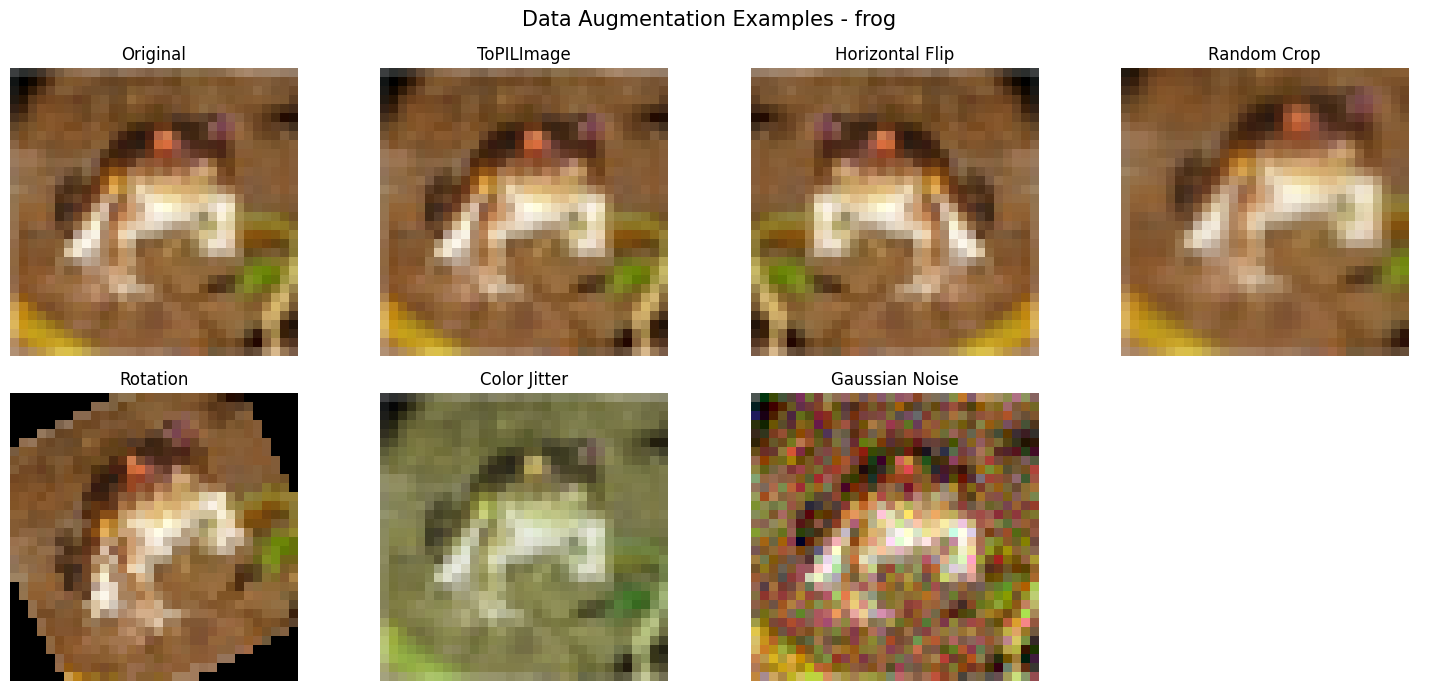

In [12]:

# Task 4: Visualizing different augmentation techniques

fig, axes = plt.subplots(2, 4, figsize=(15, 7))

for ax, (name, transform) in zip(
    axes.flat, augmentation_methods.items()
):
    augmented_image = transform(original_image)

    ax.imshow(augmented_image.permute(1, 2, 0))
    ax.set_title(name)
    ax.axis("off")

# hide unused subplot slots
for ax in list(axes.flat)[len(augmentation_methods):]:
    ax.axis("off")

plt.suptitle(
    f"Data Augmentation Examples - {class_names[original_label]}",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [13]:

# Task 4: Training and testing preprocessing pipelines

# CIFAR-10 normalization statistics
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)


class AddGaussianNoise:
    """Adds Gaussian noise to a [0,1] tensor. Training only - never applied to test data."""
    def __init__(self, std=0.02):
        self.std = std

    def __call__(self, x):
        return torch.clamp(x + torch.randn_like(x) * self.std, 0, 1)

    def __repr__(self):
        return f"AddGaussianNoise(std={self.std})"


train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop(32, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    AddGaussianNoise(std=0.02),
    transforms.Normalize(mean, std)      # must stay last (checked in the assert below)
])

# Test data: only ToTensor + the same Normalize - no random augmentation or noise
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Training transformations:")
print(train_transform)

print("\nTesting transformations:")
print(test_transform)


Training transformations:
Compose(
    RandomHorizontalFlip(p=0.5)
    RandomResizedCrop(size=(32, 32), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    ToTensor()
    AddGaussianNoise(std=0.02)
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Testing transformations:
Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


In [14]:

# Task 4: Applying transforms to the dataset

augmented_train_data = torchvision.datasets.CIFAR10(
    root=path,
    train=True,
    download=False,
    transform=train_transform
)

normalized_test_data = torchvision.datasets.CIFAR10(
    root=path,
    train=False,
    download=False,
    transform=test_transform
)

# Create DataLoaders for augmented CNN training
augmented_train_loader = DataLoader(
    augmented_train_data,
    batch_size=64,
    shuffle=True
)

normalized_test_loader = DataLoader(
    normalized_test_data,
    batch_size=64,
    shuffle=False
)


print("Augmented training images:", len(augmented_train_data))
print("Testing images:", len(normalized_test_data))
print("Training batches:", len(augmented_train_loader))
print("Testing batches:", len(normalized_test_loader))


Augmented training images: 50000
Testing images: 10000
Training batches: 782
Testing batches: 157


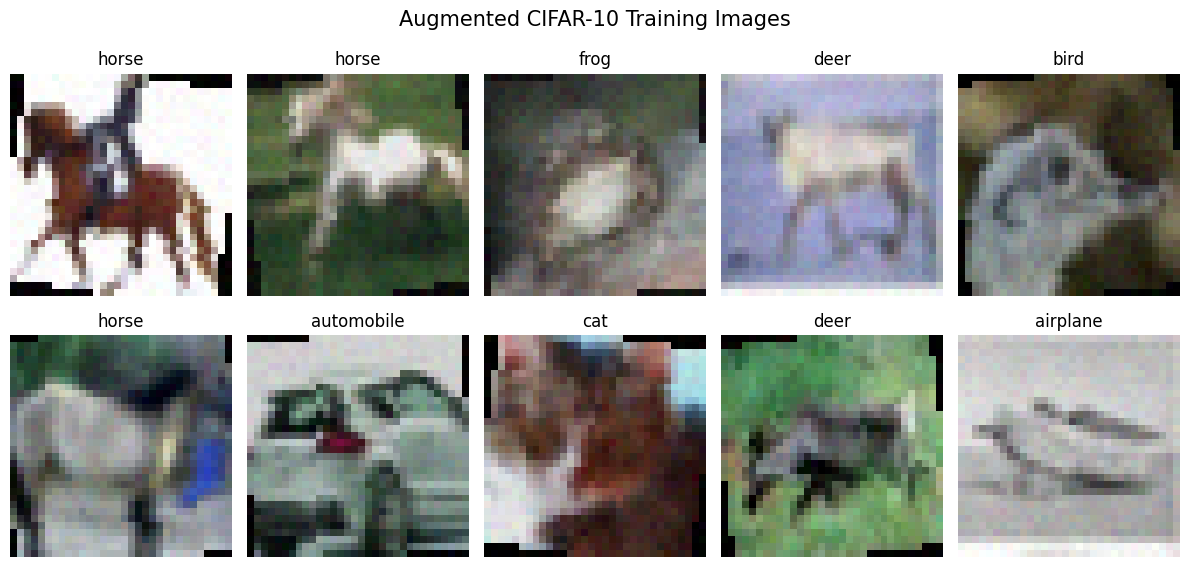

In [15]:

# Task 4: Visualize augmented training images

images, labels = next(iter(augmented_train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

mean_tensor = torch.tensor(mean).view(3, 1, 1)
std_tensor = torch.tensor(std).view(3, 1, 1)

for i, ax in enumerate(axes.flat):
    # Reverse normalization for visualization
    image = images[i] * std_tensor + mean_tensor
    image = image.clamp(0, 1)

    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.suptitle("Augmented CIFAR-10 Training Images", fontsize=15)
plt.tight_layout()
plt.show()


### Controlled Experiment: With vs. Without Data Augmentation

In [16]:

# Task 4: Baseline preprocessing without augmentation

baseline_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

baseline_train_data = torchvision.datasets.CIFAR10(
    root=path,
    train=True,
    download=False,
    transform=baseline_transform
)

print("Baseline training samples:", len(baseline_train_data))
print("Augmented training samples:", len(augmented_train_data))
print("Test samples:", len(normalized_test_data))


Baseline training samples: 50000
Augmented training samples: 50000
Test samples: 10000


In [17]:

# Task 4: DataLoaders for controlled comparison

baseline_train_loader = DataLoader(
    baseline_train_data,
    batch_size=64,
    shuffle=True
)

print("Baseline training batches:", len(baseline_train_loader))
print("Augmented training batches:", len(augmented_train_loader))
print("Testing batches:", len(normalized_test_loader))


Baseline training batches: 782
Augmented training batches: 782
Testing batches: 157


In [18]:

# Task 4: Verify experiment configuration

import pandas as pd

comparison = pd.DataFrame({
    "Configuration": ["Baseline", "Augmented"],
    "Training samples": [
        len(baseline_train_data),
        len(augmented_train_data)
    ],
    "Batch size": [64, 64],
    "Random augmentation": ["No", "Yes"],
    "Normalization": ["Same mean/std", "Same mean/std"],
    "Test dataset": ["CIFAR-10 Test", "CIFAR-10 Test"]
})

display(comparison)

assert baseline_transform.transforms[-1].mean == train_transform.transforms[-1].mean
assert baseline_transform.transforms[-1].std == train_transform.transforms[-1].std

assert len(baseline_train_data) == len(augmented_train_data)
assert len(baseline_train_loader) == len(augmented_train_loader)

print("Baseline and augmented configurations are consistent.")


,Configuration,Training samples,Batch size,Random augmentation,Normalization,Test dataset
0,Baseline,50000,64,No,Same mean/std,CIFAR-10 Test
1,Augmented,50000,64,Yes,Same mean/std,CIFAR-10 Test


Baseline and augmented configurations are consistent.


## Task 5 – Model Training & Hyperparameter Tuning


In [19]:
import time, copy
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F

SEED = 42
CLASSES = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

NUM_WORKERS = 2   # set to 0 if you run on Windows and get a DataLoader/pickle error

def get_loaders(batch_size, data="raw"):
    """data: 'raw'  = ToTensor only
             'norm' = normalized, no augmentation
             'aug'  = augmented train set (Task 4); test set is normalized only"""
    sets = {"raw":  (train_data, test_data),
            "norm": (baseline_train_data, normalized_test_data),
            "aug":  (augmented_train_data, normalized_test_data)}
    tr, te = sets[data]
    train_loader = DataLoader(tr, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)
    test_loader = DataLoader(te, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, test_loader

In [20]:
class BaselineCNN(nn.Module):
    """Small CNN: 2 conv + 2 maxpool + 3 FC layers."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


class WiderCNN(nn.Module):
    """3 conv layers (32-64-128 filters) + maxpool + dropout."""
    def __init__(self, dropout=0.3):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.drop = nn.Dropout(dropout)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = torch.flatten(x, 1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)


class DeepBNCNN(nn.Module):
    """VGG-style: double conv blocks + BatchNorm + dropout."""
    def __init__(self, dropout=0.4):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2, 2))

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


ARCHS = {"Baseline": BaselineCNN, "Wider": WiderCNN, "DeepBN": DeepBNCNN}


In [21]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, 100.0 * correct / n


def make_optimizer(name, params, lr):
    if name == "SGD":
        return optim.SGD(params, lr=lr, momentum=0.9)
    if name == "Adam":
        return optim.Adam(params, lr=lr)
    raise ValueError(name)


def run_experiment(name, arch="Baseline", lr=0.001, batch_size=64,
                   epochs=10, optimizer_name="Adam", data="raw"):
    """Train one configuration and record loss/accuracy for every epoch."""
    torch.manual_seed(SEED)
    model = ARCHS[arch]().to(device)
    train_loader, test_loader = get_loaders(batch_size, data)
    criterion = nn.CrossEntropyLoss()
    opt = make_optimizer(optimizer_name, model.parameters(), lr)

    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    best_state, best_acc = None, 0.0
    start = time.time()
    for ep in range(1, epochs + 1):
        tr = train_one_epoch(model, train_loader, criterion, opt)
        te_loss, te_acc = evaluate(model, test_loader, criterion)
        hist["train_loss"].append(tr)
        hist["test_loss"].append(te_loss)
        hist["test_acc"].append(te_acc)
        if te_acc > best_acc:
            best_acc, best_state = te_acc, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {ep:02d}/{epochs} | train loss {tr:.4f} | "
              f"test loss {te_loss:.4f} | test acc {te_acc:.2f}%")
    return {"name": name, "arch": arch, "lr": lr, "batch_size": batch_size,
            "epochs": epochs, "optimizer": optimizer_name, "data": data,
            "final_train_loss": hist["train_loss"][-1],
            "final_test_loss": hist["test_loss"][-1],
            "final_test_acc": hist["test_acc"][-1],
            "best_test_acc": best_acc, "time_s": time.time() - start,
            "hist": hist, "best_state": best_state}


In [22]:
EPOCHS = 10
results = []

#1) Architecture comparison
for arch in ARCHS:
    results.append(run_experiment(f"arch={arch}", arch=arch, epochs=EPOCHS))

# 2) Learning rate sweep (Wider CNN)
for lr in [0.01, 0.001, 0.0001]:
    results.append(run_experiment(f"lr={lr}", arch="Wider", lr=lr, epochs=EPOCHS))

# 3) Batch size sweep (Wider CNN)
for bs in [32, 64, 128, 256]:
    results.append(run_experiment(f"bs={bs}", arch="Wider", batch_size=bs, epochs=EPOCHS))

# 4) Optimizer comparison (Wider CNN)
results.append(run_experiment("opt=SGD(lr=0.01)", arch="Wider", lr=0.01,
                              optimizer_name="SGD", epochs=EPOCHS))

# 5) Longer training
results.append(run_experiment("DeepBN, 20 epochs", arch="DeepBN", epochs=20))

# 6) Effect of normalization and data augmentation (Task 4 pipelines), DeepBN, 20 epochs
results.append(run_experiment("DeepBN 20ep + norm", arch="DeepBN", epochs=20, data="norm"))
results.append(run_experiment("DeepBN 20ep + norm+aug", arch="DeepBN", epochs=20, data="aug"))


[arch=Baseline] epoch 01/10 | train loss 1.8398 | test loss 1.6100 | test acc 40.22%
[arch=Baseline] epoch 02/10 | train loss 1.5020 | test loss 1.4459 | test acc 46.99%
[arch=Baseline] epoch 03/10 | train loss 1.3946 | test loss 1.3827 | test acc 49.28%
[arch=Baseline] epoch 04/10 | train loss 1.3192 | test loss 1.2994 | test acc 52.81%
[arch=Baseline] epoch 05/10 | train loss 1.2671 | test loss 1.2368 | test acc 55.49%
[arch=Baseline] epoch 06/10 | train loss 1.2116 | test loss 1.2283 | test acc 55.50%
[arch=Baseline] epoch 07/10 | train loss 1.1756 | test loss 1.2151 | test acc 56.99%
[arch=Baseline] epoch 08/10 | train loss 1.1385 | test loss 1.1876 | test acc 58.06%
[arch=Baseline] epoch 09/10 | train loss 1.1110 | test loss 1.1640 | test acc 58.63%
[arch=Baseline] epoch 10/10 | train loss 1.0818 | test loss 1.1507 | test acc 58.71%
[arch=Wider] epoch 01/10 | train loss 1.5410 | test loss 1.2652 | test acc 54.29%
[arch=Wider] epoch 02/10 | train loss 1.1580 | test loss 1.0120 | te

In [23]:
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("hist", "best_state")}
                   for r in results])
df = df.round({"final_train_loss": 4, "final_test_loss": 4,
               "final_test_acc": 2, "best_test_acc": 2, "time_s": 1})
pd.set_option("display.width", 200)
print(df[["name", "arch", "data", "optimizer", "lr", "batch_size", "epochs",
          "final_train_loss", "final_test_loss", "final_test_acc",
          "best_test_acc", "time_s"]].to_string(index=False))
df.to_csv("task5_results.csv", index=False)

best = max(results, key=lambda r: r["best_test_acc"])
print(f"\nBEST CONFIG: {best['name']} | arch={best['arch']} | data={best['data']} | opt={best['optimizer']} | "
      f"lr={best['lr']} | batch={best['batch_size']} | epochs={best['epochs']} | "
      f"best test acc={best['best_test_acc']:.2f}%")


                  name     arch data optimizer     lr  batch_size  epochs  final_train_loss  final_test_loss  final_test_acc  best_test_acc  time_s
         arch=Baseline Baseline  raw      Adam 0.0010          64      10            1.0818           1.1507           58.71          58.71    96.0
            arch=Wider    Wider  raw      Adam 0.0010          64      10            0.4695           0.7638           75.35          75.61   102.6
           arch=DeepBN   DeepBN  raw      Adam 0.0010          64      10            0.3873           0.5549           82.01          82.34   119.3
               lr=0.01    Wider  raw      Adam 0.0100          64      10            1.4969           1.4355           48.38          48.38   102.3
              lr=0.001    Wider  raw      Adam 0.0010          64      10            0.4620           0.8216           73.86          74.72   102.3
             lr=0.0001    Wider  raw      Adam 0.0001          64      10            1.1252           1.0818    

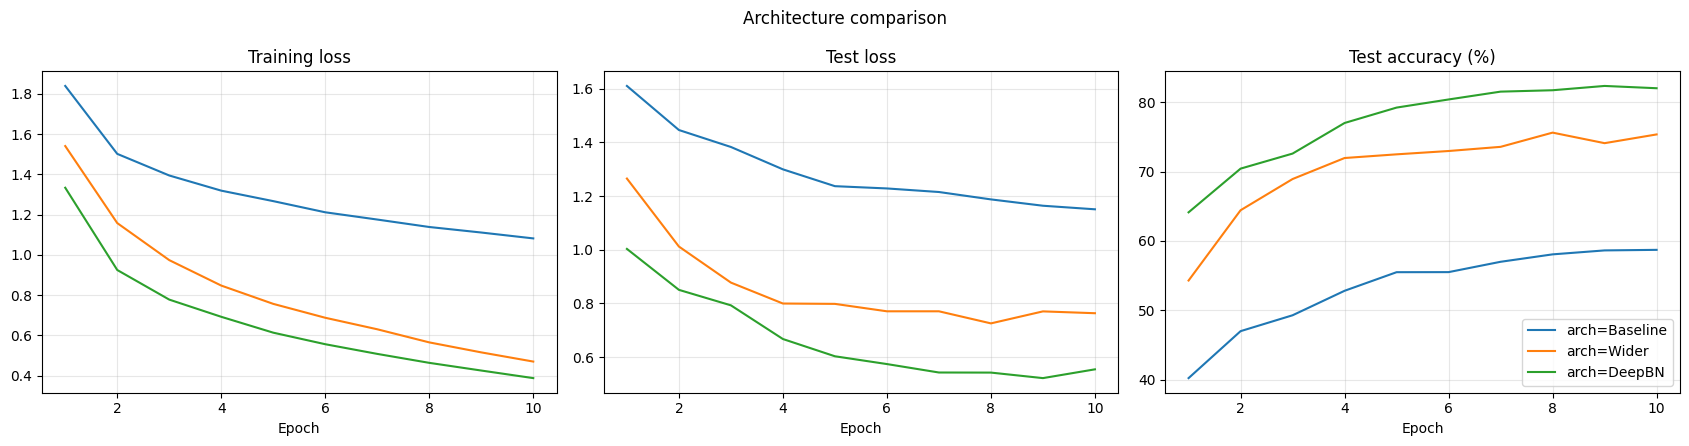

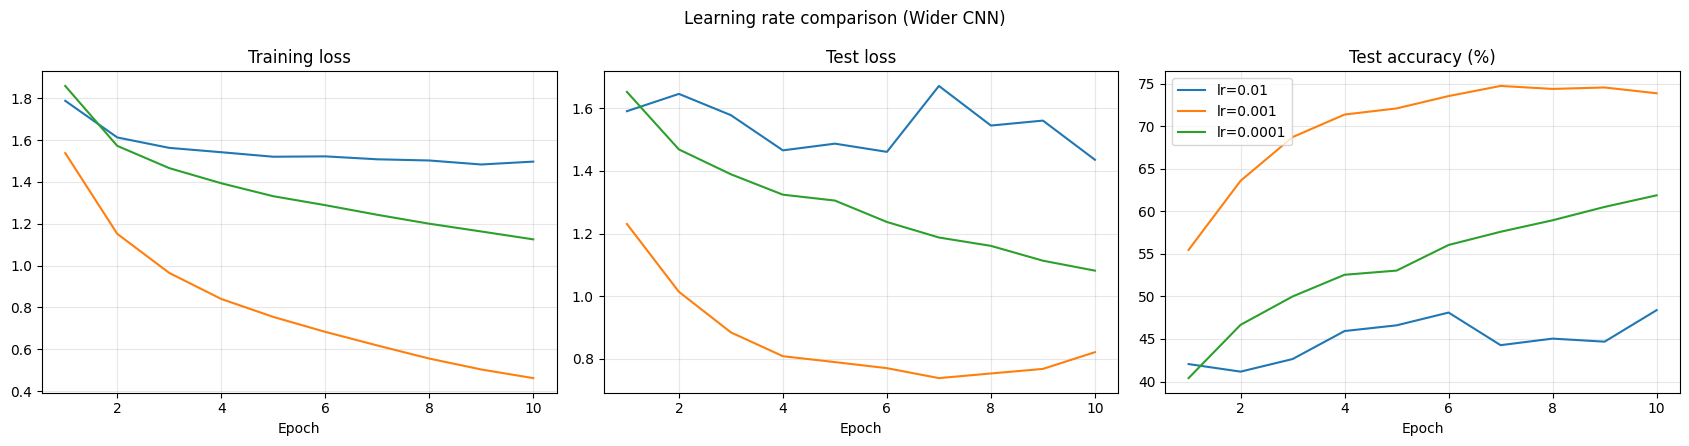

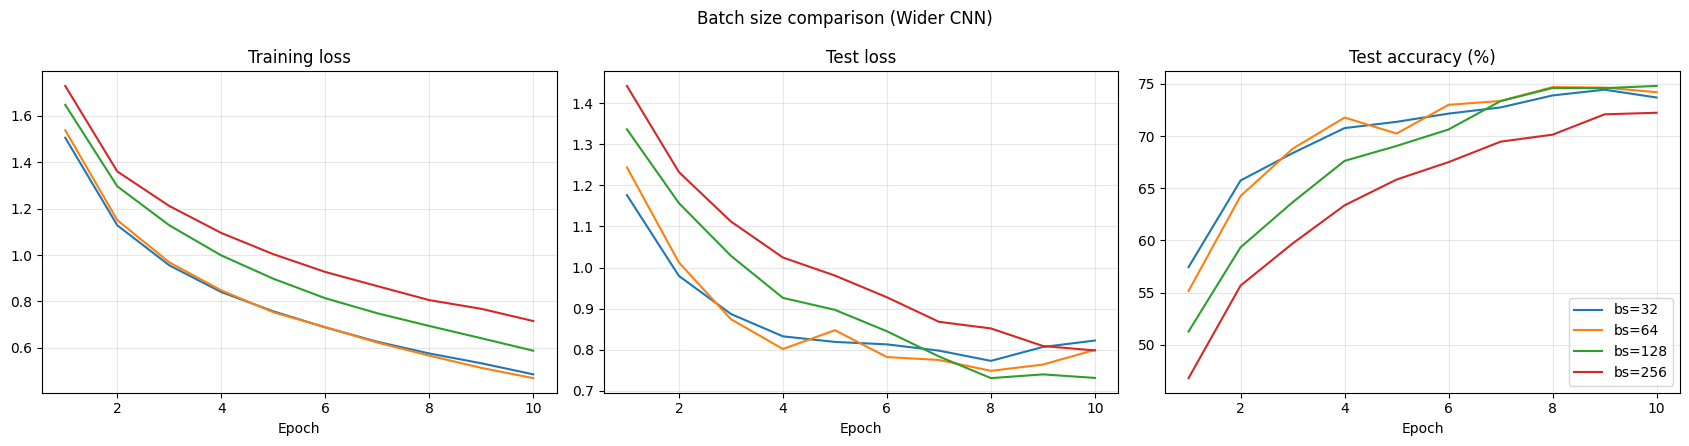

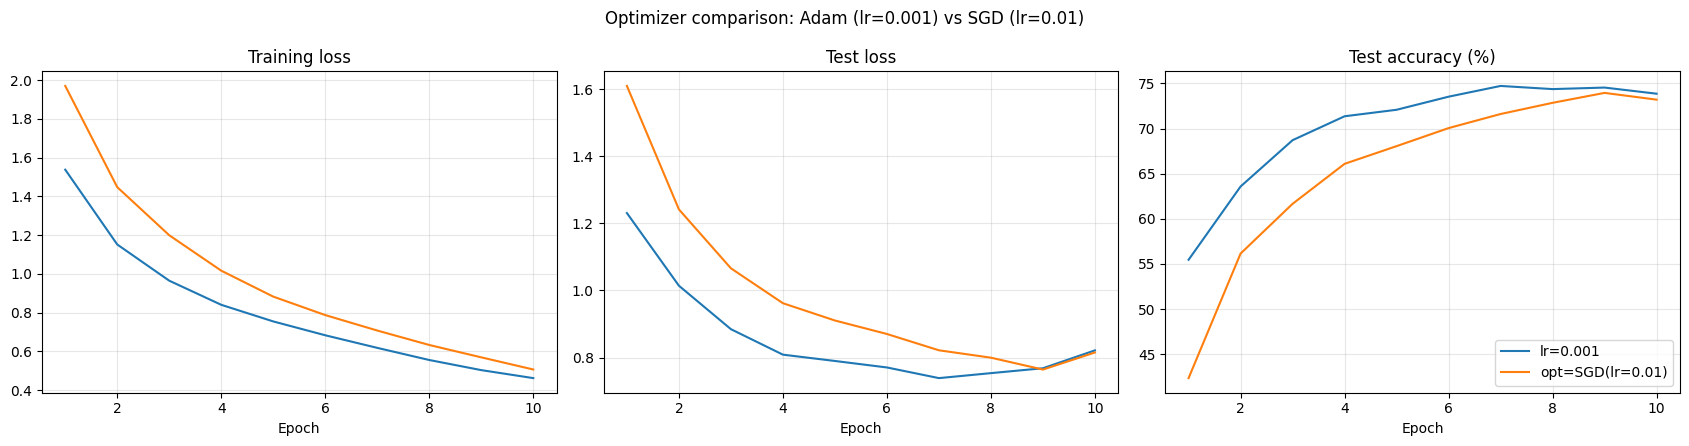

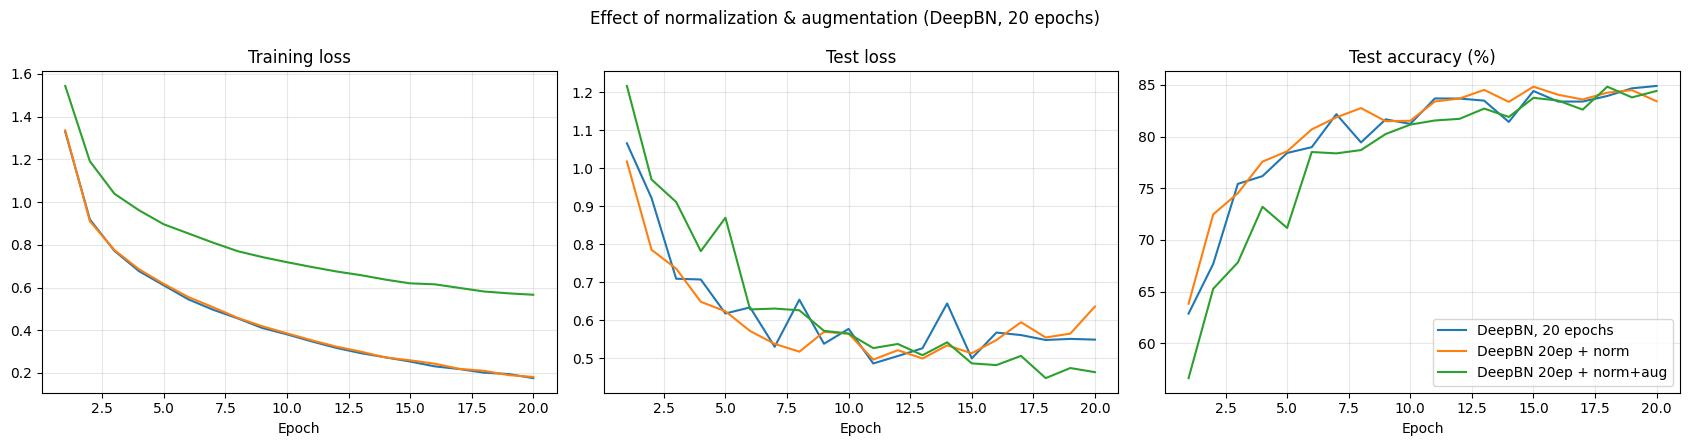

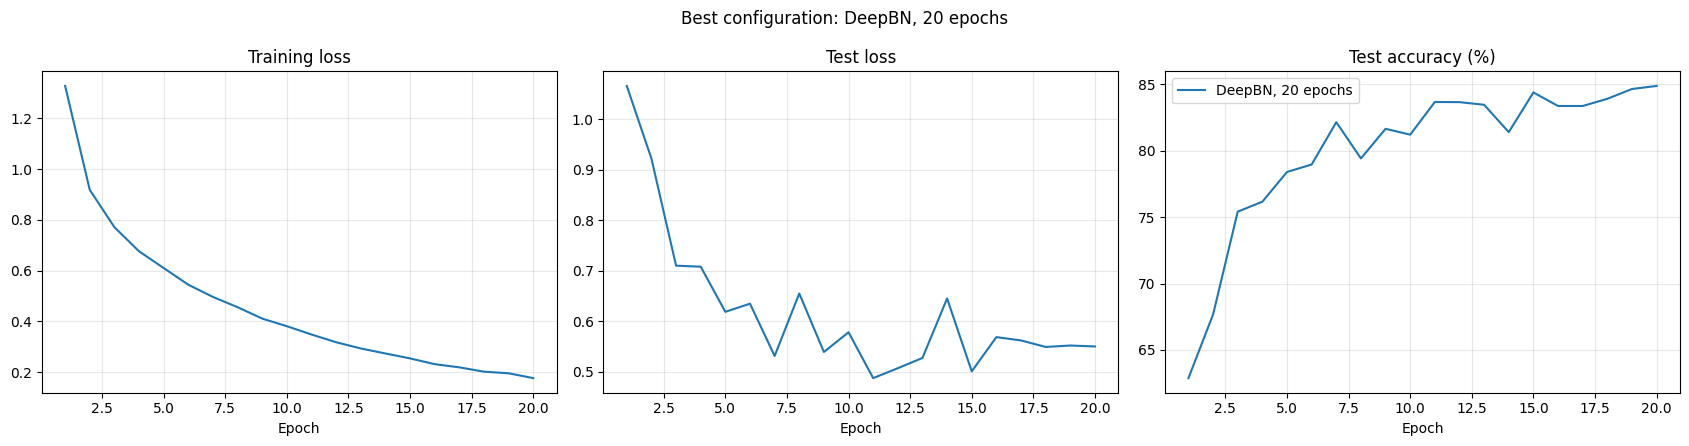

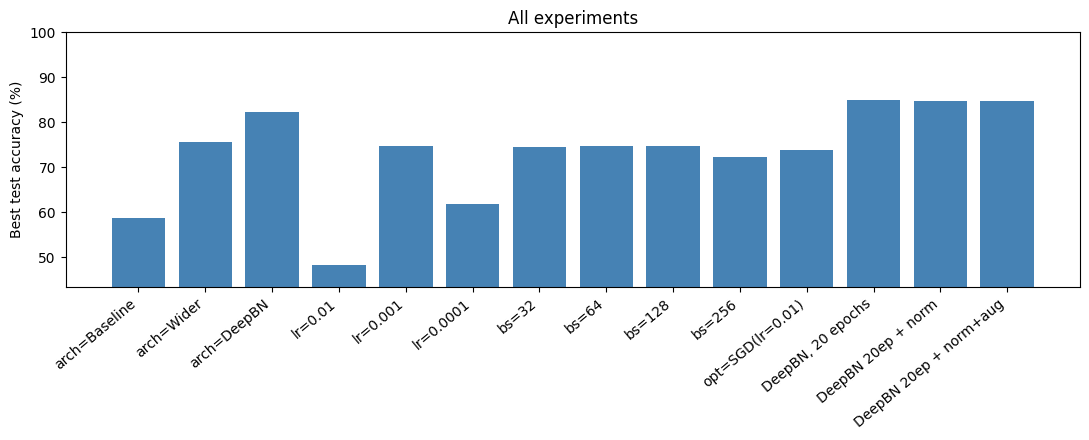

In [24]:
def plot_group(group, title, fname):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    for r in group:
        e = range(1, len(r["hist"]["train_loss"]) + 1)
        ax[0].plot(e, r["hist"]["train_loss"], label=r["name"])
        ax[1].plot(e, r["hist"]["test_loss"], label=r["name"])
        ax[2].plot(e, r["hist"]["test_acc"], label=r["name"])
    for a, t in zip(ax, ["Training loss", "Test loss", "Test accuracy (%)"]):
        a.set_title(t)
        a.set_xlabel("Epoch")
        a.grid(alpha=0.3)
    ax[2].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()


plot_group([r for r in results if r["name"].startswith("arch=")],
           "Architecture comparison", "plot_architectures.png")
plot_group([r for r in results if r["name"].startswith("lr=")],
           "Learning rate comparison (Wider CNN)", "plot_learning_rate.png")
plot_group([r for r in results if r["name"].startswith("bs=")],
           "Batch size comparison (Wider CNN)", "plot_batch_size.png")
plot_group([r for r in results if r["name"] in ("opt=SGD(lr=0.01)", "lr=0.001")],
           "Optimizer comparison: Adam (lr=0.001) vs SGD (lr=0.01)", "plot_optimizer.png")
plot_group([r for r in results if r["name"].startswith("DeepBN") and r["epochs"] == 20],
           "Effect of normalization & augmentation (DeepBN, 20 epochs)", "plot_augmentation.png")
plot_group([best], f"Best configuration: {best['name']}", "plot_best.png")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(df["name"], df["best_test_acc"], color="steelblue")
ax.set_ylabel("Best test accuracy (%)")
ax.set_title("All experiments")
ax.set_ylim(df["best_test_acc"].min() - 5, 100)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("plot_summary.png", dpi=150)
plt.show()

In [25]:
torch.save({"arch": best["arch"], "state_dict": best["best_state"]}, "best_model.pth")
print("Saved best_model.pth")


Saved best_model.pth
